In [1]:
%pip install tensorflow matplotlib seaborn scikit-learn pandas

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   - -------------------------------------- 12.1/351.2 MB 63.9 MB/s eta 0:00:06
   -- ------------------------------------- 25.7/351.2 MB 65.8 MB/s eta 0:00:05
   ---- ----------------------------------- 40.1/351.2 MB 67.6 MB/s eta 0:00:05
   ----- ---------------------------------- 49.3/351.2 MB 61.5 MB/s eta 0:00:05
   ------ --------------------------------- 58.7/351.2 MB 58.4 MB/s eta 0:00:06
   ------- -------------------------------- 66.6/351.2 MB 54.3 MB/s eta 0:00:06
   -------- ------------------------------- 72.6/351.2 MB 51.0 MB/s eta 0:00:06
   --------- ------------------------------ 79.4/351.2 MB 48.8 MB/s eta 0:00:06
   ---------- ----------------------------- 88.3/351.2 MB 47.8 MB/s eta 0:00:06
   ----------- ---------------------------- 97.8/351.2 MB 47.7 MB/s eta 0:00:06
   ----------- --------------------------- 108.0/351.2 MB 47.9 MB/s eta 0:00:06
   ------------- ------------------------- 119.8/

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


1. Cargando subconjunto de Entrenamiento (80%)...
Found 14034 files belonging to 6 classes.
Using 11228 files for training.

2. Cargando subconjunto de Validación (20%)...
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.

3. Cargando conjunto de Prueba Final (Test)...
Found 3000 files belonging to 6 classes.

Clases detectadas (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


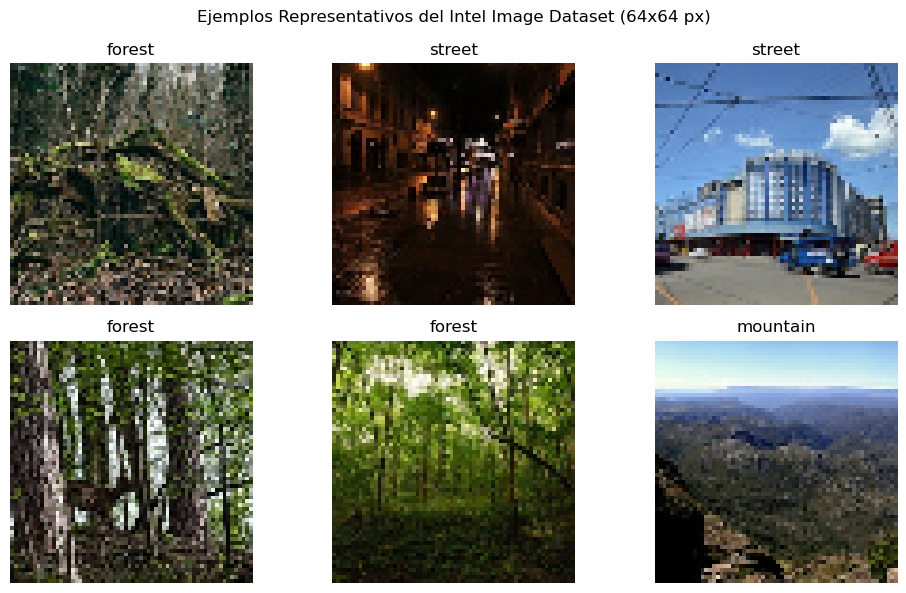

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import time
import os
from sklearn.metrics import classification_report, confusion_matrix

# 1. Definición de rutas y parámetros (Misma base de EP1 para comparación justa + Partición Validación)
TRAIN_DIR = '../data/seg_train/seg_train'
TEST_DIR = '../data/seg_test/seg_test'
BATCH_SIZE = 32
IMG_SIZE = (64, 64)
SEED = 42

print("1. Cargando subconjunto de Entrenamiento (80%)...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)

print("\n2. Cargando subconjunto de Validación (20%)...")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)

print("\n3. Cargando conjunto de Prueba Final (Test)...")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)

class_names = train_dataset.class_names
print(f"\nClases detectadas ({len(class_names)}): {class_names}")

# Visualización de ejemplos representativos (Exigido en sección b de la pauta)
plt.figure(figsize=(10, 6))
for images, labels in train_dataset.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.suptitle("Ejemplos Representativos del Intel Image Dataset (64x64 px)")
plt.tight_layout()
plt.show()

# Capa de normalización [0, 255] -> [0, 1] conservando el formato matricial 3D (64, 64, 3)
normalization_layer = tf.keras.layers.Rescaling(1./255)
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y)).cache().prefetch(AUTOTUNE)

In [ ]:
from tensorflow.keras import models, layers

# Definición de la arquitectura CNN
cnn_model = models.Sequential(name="CNN_Intel_64x64")

# Entrada explícita conservando estructura espacial (64, 64, 3)
cnn_model.add(layers.Input(shape=(64, 64, 3)))

# Bloque Convolucional 1: Extracción de bordes y colores básicos
cnn_model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv_1'))
cnn_model.add(layers.MaxPooling2D((2, 2), name='pool_1'))

# Bloque Convolucional 2: Extracción de texturas y formas simples
cnn_model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv_2'))
cnn_model.add(layers.MaxPooling2D((2, 2), name='pool_2'))

# Bloque Convolucional 3: Extracción de partes complejas de escenarios
cnn_model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same', name='conv_3'))
cnn_model.add(layers.MaxPooling2D((2, 2), name='pool_3'))

# Transición al clasificador (Aplanado de 8x8x128 = 8192 características espaciales)
cnn_model.add(layers.Flatten())

# Capas Densas Clasificadoras
cnn_model.add(layers.Dense(128, activation='relu'))
cnn_model.add(layers.Dropout(0.4)) # Regularización contra sobreajuste
cnn_model.add(layers.Dense(6, activation='softmax'))

# Compilación con los mismos hiperparámetros de optimización que el MLP para comparación justa
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "CNN_Intel_64x64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,726 (4.36 MB)

 Trainable params: 1,142,726 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Iniciando el entrenamiento de la CNN...
Epoch 1/20


c:\ProgramData\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 75ms/step - accuracy: 0.5830 - loss: 1.0816 - val_accuracy: 0.6454 - val_loss: 0.9768
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.7181 - loss: 0.7838 - val_accuracy: 0.6953 - val_loss: 0.8215
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.7695 - loss: 0.6533 - val_accuracy: 0.7520 - val_loss: 0.6609
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.8006 - loss: 0.5721 - val_accuracy: 0.7634 - val_loss: 0.6451
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.8247 - loss: 0.5018 - val_accuracy: 0.7947 - val_loss: 0.5945
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.8403 - loss: 0.4558 - val_accuracy: 0.7894 - val_loss: 0.6266
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.8631 - loss: 0.3817 - val_accuracy: 0.8019 - val_loss: 0.6335
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.8765 - loss: 0.3416 - val_accurac

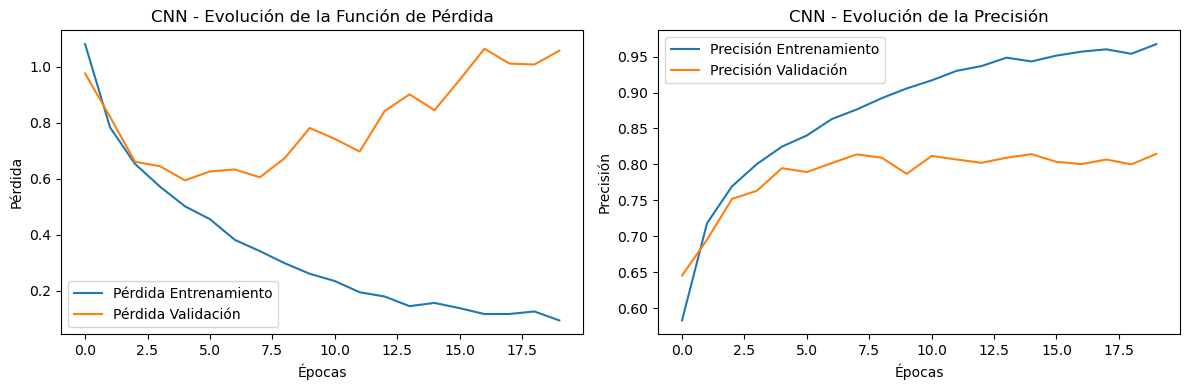

In [3]:
EPOCHS = 20

print("Iniciando el entrenamiento de la CNN...")
start_time_cnn = time.time()

history_cnn = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

tiempo_cnn = time.time() - start_time_cnn
print(f"\nEntrenamiento finalizado en {tiempo_cnn:.2f} segundos.")

# Guardar el modelo CNN entrenado
os.makedirs('../models', exist_ok=True)
cnn_model.save('../models/cnn_intel_model.keras')
print("Modelo CNN guardado exitosamente en '../models/cnn_intel_model.keras'")

# Graficar el proceso de aprendizaje (Loss y Accuracy)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history_cnn.history['val_loss'], label='Pérdida Validación')
plt.title('CNN - Evolución de la Función de Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history_cnn.history['val_accuracy'], label='Precisión Validación')
plt.title('CNN - Evolución de la Precisión')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.tight_layout()
plt.show()

Generando predicciones de la CNN sobre el set de prueba...

--- REPORTE DE CLASIFICACIÓN - CNN ---
              precision    recall  f1-score   support

   buildings       0.78      0.80      0.79       437
      forest       0.90      0.97      0.93       474
     glacier       0.78      0.73      0.75       553
    mountain       0.75      0.75      0.75       525
         sea       0.79      0.80      0.79       510
      street       0.85      0.80      0.83       501

    accuracy                           0.81      3000
   macro avg       0.81      0.81      0.81      3000
weighted avg       0.81      0.81      0.80      3000



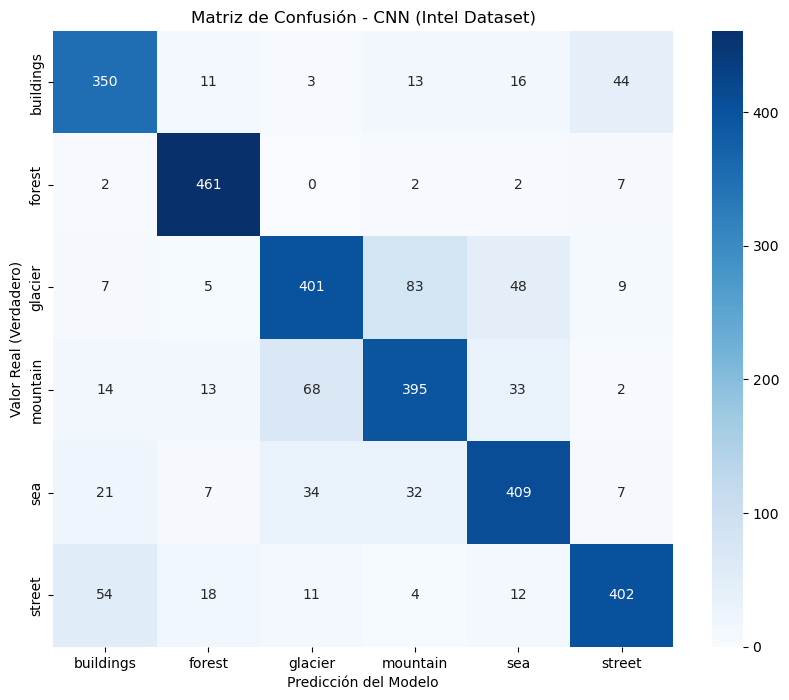


Cargando modelo MLP de la Evaluación 1 para comparación...

=== TABLA COMPARATIVA: MLP vs CNN ===


,Métrica / Característica,Modelo MLP (EP1),Modelo CNN (EP2)
0,Cantidad Total de Parámetros,"6,456,966","1,142,726"
1,Accuracy (Prueba),0.5177,0.8060
2,Precision Macro,0.5157,0.8065
3,Recall Macro,0.5199,0.8092
4,F1-Score Macro,0.4979,0.8073


In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# 1. Extraer etiquetas reales y predicciones de la CNN sobre Test
y_true = []
y_pred_probs_cnn = []

print("Generando predicciones de la CNN sobre el set de prueba...")
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
    preds = cnn_model.predict(images, verbose=0)
    y_pred_probs_cnn.extend(preds)

y_true = np.array(y_true)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

print("\n--- REPORTE DE CLASIFICACIÓN - CNN ---")
print(classification_report(y_true, y_pred_cnn, target_names=class_names))

# Matriz de Confusión CNN
cm_cnn = confusion_matrix(y_true, y_pred_cnn)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión - CNN (Intel Dataset)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Verdadero)')
plt.show()

# 2. Cargar el modelo MLP de la Evaluación Parcial 1 para comparación directa
mlp_path = '../models/mlp_intel_model.keras'
if os.path.exists(mlp_path):
    print("\nCargando modelo MLP de la Evaluación 1 para comparación...")
    mlp_model = tf.keras.models.load_model(mlp_path)
    
    y_pred_probs_mlp = mlp_model.predict(test_dataset, verbose=0)
    y_pred_mlp = np.argmax(y_pred_probs_mlp, axis=1)
    
    # Tabla comparativa automática entre MLP y CNN
    comparacion = pd.DataFrame({
        'Métrica / Característica': [
            'Cantidad Total de Parámetros',
            'Accuracy (Prueba)',
            'Precision Macro',
            'Recall Macro',
            'F1-Score Macro'
        ],
        'Modelo MLP (EP1)': [
            f"{mlp_model.count_params():,}",
            f"{accuracy_score(y_true, y_pred_mlp):.4f}",
            f"{precision_score(y_true, y_pred_mlp, average='macro'):.4f}",
            f"{recall_score(y_true, y_pred_mlp, average='macro'):.4f}",
            f"{f1_score(y_true, y_pred_mlp, average='macro'):.4f}"
        ],
        'Modelo CNN (EP2)': [
            f"{cnn_model.count_params():,}",
            f"{accuracy_score(y_true, y_pred_cnn):.4f}",
            f"{precision_score(y_true, y_pred_cnn, average='macro'):.4f}",
            f"{recall_score(y_true, y_pred_cnn, average='macro'):.4f}",
            f"{f1_score(y_true, y_pred_cnn, average='macro'):.4f}"
        ]
    })
    print("\n=== TABLA COMPARATIVA: MLP vs CNN ===")
    display(comparacion)
else:
    print("Nota: No se encontró '../models/mlp_intel_model.keras'. Asegúrate de tenerlo en la carpeta models.")

In [ ]:
# --- SECCIÓN g: VISUALIZACIÓN DE FEATURE MAPS ---
# Tomamos una imagen del set de prueba
for images, labels in test_dataset.take(1):
    sample_image = images[0:1] # (1, 64, 64, 3)
    sample_label = class_names[labels[0].numpy()]

# Creamos un sub-modelo que devuelve las activaciones de las 3 capas convolucionales
layer_names = ['conv_1', 'conv_2', 'conv_3']
layer_outputs = [cnn_model.get_layer(name).output for name in layer_names]
feature_map_model = models.Model(inputs=cnn_model.inputs, outputs=layer_outputs)

feature_maps = feature_map_model.predict(sample_image, verbose=0)

# Graficamos la imagen original y 4 filtros por cada capa convolucional
plt.figure(figsize=(3, 3))
plt.imshow(sample_image[0].numpy())
plt.title(f"Imagen Original: {sample_label}")
plt.axis('off')
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
fig.suptitle(f'Evolución Jerárquica de Feature Maps (Clase: {sample_label})', fontsize=14)

for row, (name, fmap) in enumerate(zip(layer_names, feature_maps)):
    for col in range(4):
        ax = axes[row, col]
        ax.imshow(fmap[0, :, :, col], cmap='viridis')
        ax.set_title(f"{name} (Filtro {col+1})")
        ax.axis('off')
plt.tight_layout()
plt.show()

# --- SECCIÓN h: ANÁLISIS DE ACIERTOS Y ERRORES ---
# Desempaquetamos imágenes de prueba para mostrar ejemplos reales
all_test_images = np.concatenate([x.numpy() for x, y in test_dataset], axis=0)
correct_idx = np.where(y_pred_cnn == y_true)[0]
incorrect_idx = np.where(y_pred_cnn != y_true)[0]

plt.figure(figsize=(12, 5))
# 3 Aciertos en la fila superior
for i, idx in enumerate(correct_idx[:3]):
    ax = plt.subplot(2, 3, i + 1)
    plt.imshow(all_test_images[idx])
    conf = np.max(y_pred_probs_cnn[idx]) * 100
    plt.title(f"ACIERTO\nReal: {class_names[y_true[idx]]}\nPred: {class_names[y_pred_cnn[idx]]} ({conf:.1f}%)", color='green', fontsize=9)
    plt.axis('off')

# 3 Errores en la fila inferior
for i, idx in enumerate(incorrect_idx[:3]):
    ax = plt.subplot(2, 3, i + 4)
    plt.imshow(all_test_images[idx])
    conf = np.max(y_pred_probs_cnn[idx]) * 100
    plt.title(f"ERROR\nReal: {class_names[y_true[idx]]}\nPred: {class_names[y_pred_cnn[idx]]} ({conf:.1f}%)", color='red', fontsize=9)
    plt.axis('off')
plt.suptitle("Análisis Visual de Predicciones: Correctas vs. Incorrectas", fontsize=13)
plt.tight_layout()
plt.show()